In [1]:
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

c:\Users\Roko Vrdoljak\Desktop\neumre\local-vs-global-skin-lesions\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "pyproject.toml").exists()
)

DATA_DIR = ROOT / "data"

IMAGE_DIRS = [
    DATA_DIR / "HAM10000_images_part_1",
    DATA_DIR / "HAM10000_images_part_2",
]

MASK_DIR = DATA_DIR / "HAM10000_segmentations_lesion_tschandl"
METADATA_PATH = DATA_DIR / "HAM10000_metadata.csv"

print("Project root:", ROOT)
print("Data directory:", DATA_DIR)
print("Metadata exists:", METADATA_PATH.is_file())

for image_dir in IMAGE_DIRS:
    print(f"{image_dir.name} exists:", image_dir.is_dir())

print("Mask directory exists:", MASK_DIR.is_dir())

Project root: c:\Users\Roko Vrdoljak\Desktop\neumre\local-vs-global-skin-lesions
Data directory: c:\Users\Roko Vrdoljak\Desktop\neumre\local-vs-global-skin-lesions\data
Metadata exists: True
HAM10000_images_part_1 exists: True
HAM10000_images_part_2 exists: True
Mask directory exists: True


In [7]:
image_files = sorted(
    path
    for image_dir in IMAGE_DIRS
    for path in image_dir.glob("*.jpg")
)

mask_files = sorted(MASK_DIR.glob("*.png"))

print(f"Image files found: {len(image_files):,}")
print(f"Mask files found: {len(mask_files):,}")
print(f"Metadata available: {METADATA_PATH.is_file()}")

Image files found: 10,015
Mask files found: 10,015
Metadata available: True


## 1. Dataset Integrity

First, we check if all the data is there and if the images, masks and metadata match correctly.

We start by looking at the metadata and checking how many images are in the dataset.

In [8]:
metadata = pl.read_csv(METADATA_PATH)

print("Number of metadata records:", metadata.height)
print("Number of columns:", metadata.width)

print("\nColumn names:")
print(metadata.columns)

metadata.head()

Number of metadata records: 10015
Number of columns: 8

Column names:
['lesion_id', 'image_id', 'dx', 'dx_type', 'age', 'sex', 'localization', 'dataset']


lesion_id,image_id,dx,dx_type,age,sex,localization,dataset
str,str,str,str,f64,str,str,str
"""HAM_0000118""","""ISIC_0027419""","""bkl""","""histo""",80.0,"""male""","""scalp""","""vidir_modern"""
"""HAM_0000118""","""ISIC_0025030""","""bkl""","""histo""",80.0,"""male""","""scalp""","""vidir_modern"""
"""HAM_0002730""","""ISIC_0026769""","""bkl""","""histo""",80.0,"""male""","""scalp""","""vidir_modern"""
"""HAM_0002730""","""ISIC_0025661""","""bkl""","""histo""",80.0,"""male""","""scalp""","""vidir_modern"""
"""HAM_0001466""","""ISIC_0031633""","""bkl""","""histo""",75.0,"""male""","""ear""","""vidir_modern"""


### 1.1 Metadata and image consistency

We check if all images listed in the metadata are actually in the dataset. We also check if there are any extra or duplicate images.

In [9]:
metadata_ids = metadata["image_id"].to_list()
file_ids = [path.stem for path in image_files]

metadata_id_set = set(metadata_ids)
file_id_set = set(file_ids)

missing_images = sorted(metadata_id_set - file_id_set)
extra_images = sorted(file_id_set - metadata_id_set)

duplicate_metadata_ids = len(metadata_ids) - len(metadata_id_set)
duplicate_file_ids = len(file_ids) - len(file_id_set)

print("Metadata records:", len(metadata_ids))
print("Unique metadata image IDs:", len(metadata_id_set))
print("Image files:", len(file_ids))
print("Unique image file IDs:", len(file_id_set))

print("\nMissing images:", len(missing_images))
print("Extra images:", len(extra_images))
print("Duplicate metadata image IDs:", duplicate_metadata_ids)
print("Duplicate image file IDs:", duplicate_file_ids)

Metadata records: 10015
Unique metadata image IDs: 10015
Image files: 10015
Unique image file IDs: 10015

Missing images: 0
Extra images: 0
Duplicate metadata image IDs: 0
Duplicate image file IDs: 0


Metadata records: 10015
Unique metadata image IDs: 10015
Image files: 10015
Unique image file IDs: 10015

Missing images: 0
Extra images: 0
Duplicate metadata image IDs: 0
Duplicate image file IDs: 0

### 1.2 Segmentation mask consistency

We check if every image has its own segmentation mask. We also check if any masks are missing, extra or duplicated.

In [10]:
print("Example mask filenames:")
for path in mask_files[:5]:
    print(path.name)

Example mask filenames:
ISIC_0024306_segmentation.png
ISIC_0024307_segmentation.png
ISIC_0024308_segmentation.png
ISIC_0024309_segmentation.png
ISIC_0024310_segmentation.png


In [11]:
mask_ids = [
    path.stem.removesuffix("_segmentation")
    for path in mask_files
]

mask_id_set = set(mask_ids)

missing_masks = sorted(metadata_id_set - mask_id_set)
extra_masks = sorted(mask_id_set - metadata_id_set)

duplicate_mask_ids = len(mask_ids) - len(mask_id_set)

print("Metadata image IDs:", len(metadata_id_set))
print("Mask files:", len(mask_ids))
print("Unique mask IDs:", len(mask_id_set))

print("\nMissing masks:", len(missing_masks))
print("Extra masks:", len(extra_masks))
print("Duplicate mask IDs:", duplicate_mask_ids)

Metadata image IDs: 10015
Mask files: 10015
Unique mask IDs: 10015

Missing masks: 0
Extra masks: 0
Duplicate mask IDs: 0


**Findings:**

- All 10,015 images have matching metadata and segmentation masks.
- There are no missing or extra masks.
- We didn't find any duplicate mask IDs.
- The image and mask filenames match the metadata.

We will check if the files can be opened correctly and look at the mask quality in the next steps.

### 1.3 Image decoding, dimensions and color modes

We check if all images can be opened without errors. We also check their sizes and color modes to see if there are any differences that could cause problems when preparing images for the model.

In [12]:
from collections import Counter

image_dimensions = Counter()
image_modes = Counter()
corrupted_images = []

for path in tqdm(image_files, desc="Checking images"):
    try:
        with Image.open(path) as img:
            img.load()

            image_dimensions[img.size] += 1
            image_modes[img.mode] += 1

    except Exception as e:
        corrupted_images.append((path.name, str(e)))

print("Images checked:", len(image_files))
print("Corrupted images:", len(corrupted_images))

print("\nImage dimensions:")
for dimensions, count in image_dimensions.most_common():
    print(f"{dimensions}: {count} images")

print("\nImage color modes:")
for mode, count in image_modes.most_common():
    print(f"{mode}: {count} images")

if corrupted_images:
    print("\nExamples of corrupted images:")
    for name, error in corrupted_images[:5]:
        print(name, error)

Checking images: 100%|██████████| 10015/10015 [00:46<00:00, 216.47it/s]

Images checked: 10015
Corrupted images: 0

Image dimensions:
(600, 450): 10015 images

Image color modes:
RGB: 10015 images


**Findings:**

- All 10,015 images can be opened without errors.
- We didn't find any corrupted images.
- All images have the same size of 600 × 450 pixels.
- All images use RGB colors.
- The images have a 4:3 aspect ratio.

All images have the same size and color format, so there are no differences there. 

### 1.4 Segmentation mask decoding and dimensions

We check if all segmentation masks can be opened without errors. We also check their sizes and color modes, and see if each mask has the same dimensions as its image.

In [13]:
mask_dimensions = Counter()
mask_modes = Counter()
corrupted_masks = []
dimension_mismatches = []

image_sizes = {}

for path in image_files:
    with Image.open(path) as img:
        image_sizes[path.stem] = img.size

for path in tqdm(mask_files, desc="Checking masks"):
    try:
        with Image.open(path) as mask:
            mask.load()

            mask_dimensions[mask.size] += 1
            mask_modes[mask.mode] += 1

            image_id = path.stem.removesuffix("_segmentation")

            if mask.size != image_sizes[image_id]:
                dimension_mismatches.append(path.name)

    except Exception as e:
        corrupted_masks.append((path.name, str(e)))

print("Masks checked:", len(mask_files))
print("Corrupted masks:", len(corrupted_masks))
print("Dimension mismatches:", len(dimension_mismatches))

print("\nMask dimensions:")
for dimensions, count in mask_dimensions.most_common():
    print(f"{dimensions}: {count} masks")

print("\nMask color modes:")
for mode, count in mask_modes.most_common():
    print(f"{mode}: {count} masks")

if corrupted_masks:
    print("\nExamples of corrupted masks:")
    for name, error in corrupted_masks[:5]:
        print(name, error)

Checking masks: 100%|██████████| 10015/10015 [00:04<00:00, 2305.84it/s]

Masks checked: 10015
Corrupted masks: 0
Dimension mismatches: 0

Mask dimensions:
(600, 450): 10015 masks

Mask color modes:
L: 9613 masks
P: 402 masks


**Findings:**

- All 10,015 masks can be opened without errors.
- We didn't find any corrupted masks.
- All masks have the same size of 600 × 450 pixels, just like the original images.
- 9,613 masks use grayscale mode (L), while 402 use palette mode (P).

All masks can be opened and their sizes match the images. We still need to check the pixel values and see if the masks are correct.

### 1.5 Segmentation mask pixel values

We check the pixel values in both grayscale and palette masks to see if they are binary masks, meaning they only separate the lesion from the background.

In [14]:
from collections import defaultdict

masks_by_mode = defaultdict(list)

for path in mask_files:
    with Image.open(path) as mask:
        masks_by_mode[mask.mode].append(path)

for mode in ["L", "P"]:
    print(f"\nMask mode: {mode}")

    for path in masks_by_mode[mode][:3]:
        with Image.open(path) as mask:
            raw_values = np.unique(np.array(mask))
            grayscale_values = np.unique(np.array(mask.convert("L")))

        print(f"\n{path.name}")
        print("Raw pixel values:", raw_values)
        print("Grayscale pixel values:", grayscale_values)


Mask mode: L

ISIC_0024306_segmentation.png
Raw pixel values: [  0 255]
Grayscale pixel values: [  0 255]

ISIC_0024307_segmentation.png
Raw pixel values: [  0 255]
Grayscale pixel values: [  0 255]

ISIC_0024308_segmentation.png
Raw pixel values: [  0 255]
Grayscale pixel values: [  0 255]

Mask mode: P

ISIC_0024316_segmentation.png
Raw pixel values: [  0 255]
Grayscale pixel values: [  0 255]

ISIC_0024317_segmentation.png
Raw pixel values: [  0 255]
Grayscale pixel values: [  0 255]

ISIC_0024318_segmentation.png
Raw pixel values: [  0 255]
Grayscale pixel values: [  0 255]


In [15]:
non_binary_masks = []
empty_masks = []
full_masks = []

for path in tqdm(mask_files, desc="Checking mask values"):
    with Image.open(path) as mask:
        mask_array = np.array(mask.convert("L"))

    unique_values = np.unique(mask_array)

    if not np.all(np.isin(unique_values, [0, 255])):
        non_binary_masks.append((path.name, unique_values))

    if np.all(mask_array == 0):
        empty_masks.append(path.name)

    if np.all(mask_array == 255):
        full_masks.append(path.name)

print("Masks checked:", len(mask_files))
print("Non-binary masks:", len(non_binary_masks))
print("Empty masks:", len(empty_masks))
print("Completely filled masks:", len(full_masks))

if non_binary_masks:
    print("\nExamples of non-binary masks:")
    for name, values in non_binary_masks[:5]:
        print(name, values)

Checking mask values: 100%|██████████| 10015/10015 [00:23<00:00, 423.86it/s]

Masks checked: 10015
Non-binary masks: 0
Empty masks: 0
Completely filled masks: 2


**Findings:**

- All 10,015 masks only have pixel values of 0 and 255 after converting them to grayscale.
- We didn't find any empty masks.
- Two masks are completely filled (100% of pixels are part of the lesion).
- We need to look at these two masks to check if they are correct or if they should be removed.

In [16]:
print("Completely filled masks:")
for name in full_masks:
    print(name)

Completely filled masks:
ISIC_0026042_segmentation.png
ISIC_0029819_segmentation.png


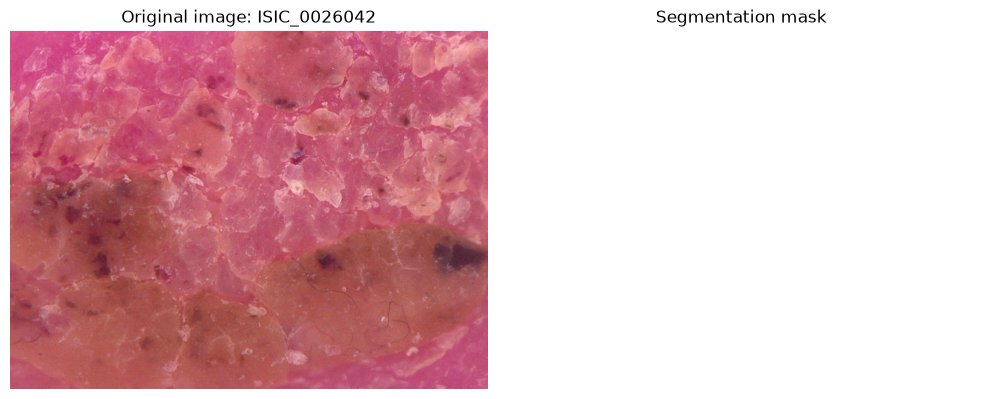

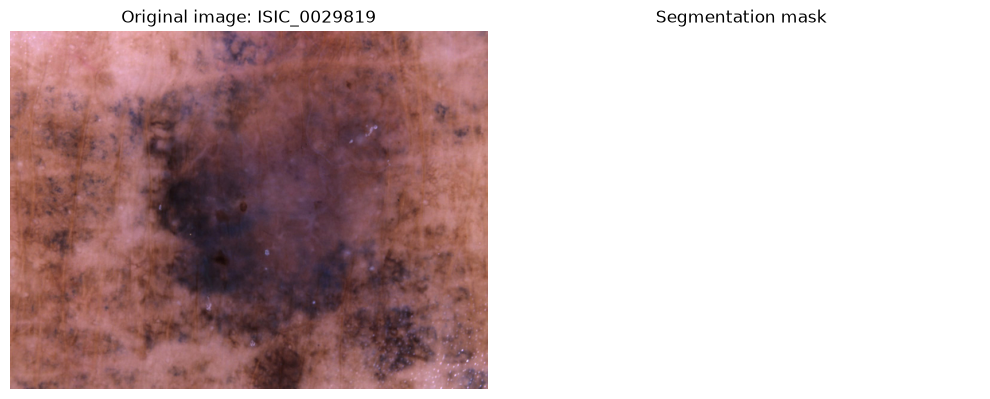

In [17]:
image_lookup = {
    path.stem: path
    for path in image_files
}

for mask_name in full_masks:
    image_id = Path(mask_name).stem.removesuffix("_segmentation")

    image_path = image_lookup[image_id]
    mask_path = MASK_DIR / mask_name

    with Image.open(image_path) as img:
        image_array = np.array(img.convert("RGB"))

    with Image.open(mask_path) as mask:
        mask_array = np.array(mask.convert("L"))

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    axes[0].imshow(image_array)
    axes[0].set_title(f"Original image: {image_id}")
    axes[0].axis("off")

    axes[1].imshow(mask_array, cmap="gray", vmin=0, vmax=255)
    axes[1].set_title("Segmentation mask")
    axes[1].axis("off")

    plt.tight_layout()
    plt.show()

**Mask quality findings:**

- All 10,015 masks only contain values 0 and 255 after converting them to grayscale.
- We didn't find any empty masks.
- Two masks are completely filled:
  - ISIC_0026042
  - ISIC_0029819


## 2. Lesion Scale Analysis

We check how much of each image is covered by the lesion. 

In [18]:
lesion_records = []

for path in tqdm(mask_files, desc="Measuring lesion areas"):
    image_id = path.stem.removesuffix("_segmentation")

    with Image.open(path) as mask:
        mask_array = np.array(mask.convert("L"))

    lesion_pixels = np.count_nonzero(mask_array)
    total_pixels = mask_array.size

    lesion_records.append({
        "image_id": image_id,
        "lesion_area_pixels": lesion_pixels,
        "lesion_area_fraction": lesion_pixels / total_pixels,
    })

lesion_df = pl.DataFrame(lesion_records)

print("Lesions measured:", lesion_df.height)

print("\nLesion area statistics:")
print(
    lesion_df.select(
        pl.col("lesion_area_fraction").min().alias("min"),
        pl.col("lesion_area_fraction").median().alias("median"),
        pl.col("lesion_area_fraction").mean().alias("mean"),
        pl.col("lesion_area_fraction").max().alias("max"),
        pl.col("lesion_area_fraction").std().alias("std"),
    )
)

Measuring lesion areas: 100%|██████████| 10015/10015 [00:07<00:00, 1299.36it/s]

Lesions measured: 10015

Lesion area statistics:
shape: (1, 5)
┌──────────┬──────────┬──────────┬─────┬──────────┐
│ min      ┆ median   ┆ mean     ┆ max ┆ std      │
│ ---      ┆ ---      ┆ ---      ┆ --- ┆ ---      │
│ f64      ┆ f64      ┆ f64      ┆ f64 ┆ f64      │
╞══════════╪══════════╪══════════╪═════╪══════════╡
│ 0.003856 ┆ 0.222307 ┆ 0.266325 ┆ 1.0 ┆ 0.188419 │
└──────────┴──────────┴──────────┴─────┴──────────┘


**Lesion area findings:**

- Lesions cover between 0.39% and 100% of the image.
- The median lesion area is 22.23%, and the average is 26.63%.
- The standard deviation is 18.84 percentage points.
- Lesion sizes are quite different across the dataset.
- Two masks that we found earlier cover the whole image.

Because lesion sizes vary a lot, we need to keep this in mind when resizing and preparing images for the model.

### 2.1 Distribution of lesion area

We make a graph to see how lesion sizes are distributed in the dataset. 

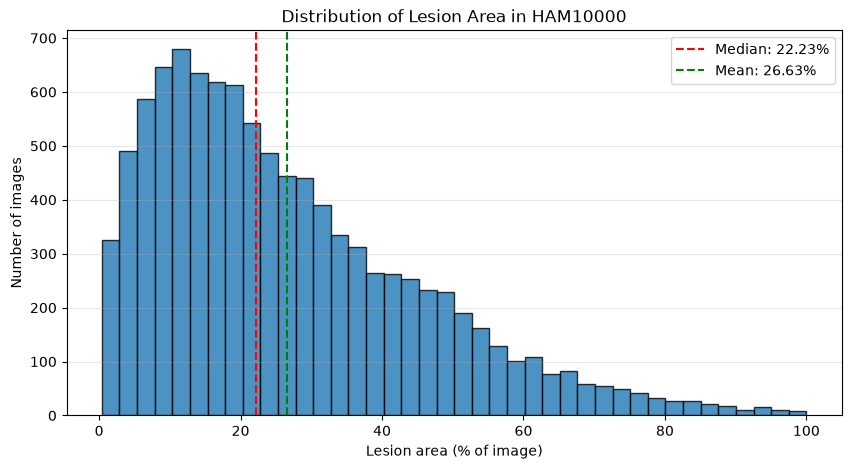

In [19]:
area_percentages = (
    lesion_df["lesion_area_fraction"].to_numpy() * 100
)

plt.figure(figsize=(10, 5))

plt.hist(
    area_percentages,
    bins=40,
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    np.median(area_percentages),
    color="red",
    linestyle="--",
    label=f"Median: {np.median(area_percentages):.2f}%"
)

plt.axvline(
    np.mean(area_percentages),
    color="green",
    linestyle="--",
    label=f"Mean: {np.mean(area_percentages):.2f}%"
)

plt.xlabel("Lesion area (% of image)")
plt.ylabel("Number of images")
plt.title("Distribution of Lesion Area in HAM10000")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

### 2.2 Lesion Area by Diagnostic Class

We compare lesion area distributions across the seven
diagnostic classes to identify differences in lesion scale.

In [25]:
lesion_with_metadata = lesion_df.join(
    metadata.select("image_id", "dx"),
    on="image_id",
    how="inner"
)

class_area_stats = (
    lesion_with_metadata
    .group_by("dx")
    .agg(
        pl.len().alias("count"),
        (pl.col("lesion_area_fraction").mean() * 100)
            .round(2).alias("mean_area_pct"),
        (pl.col("lesion_area_fraction").median() * 100)
            .round(2).alias("median_area_pct"),
        (pl.col("lesion_area_fraction").min() * 100)
            .round(2).alias("min_area_pct"),
        (pl.col("lesion_area_fraction").max() * 100)
            .round(2).alias("max_area_pct"),
    )
    .sort("median_area_pct", descending=True)
)

print("Images matched:", lesion_with_metadata.height)
class_area_stats

Images matched: 10015


dx,count,mean_area_pct,median_area_pct,min_area_pct,max_area_pct
str,u32,f64,f64,f64,f64
"""akiec""",327,40.3,40.09,2.18,97.04
"""mel""",1113,32.44,30.06,0.56,100.0
"""bkl""",1099,31.96,29.1,0.85,100.0
"""df""",115,31.19,28.36,2.67,89.98
"""bcc""",514,26.01,22.68,0.58,93.61
"""nv""",6705,24.34,19.99,0.39,99.15
"""vasc""",142,15.2,9.88,0.96,90.2


**Findings:**

- Lesion sizes are quite different between diagnostic classes.
- `akiec` has the highest median lesion area (40.09%).
- `vasc` has the lowest median lesion area (9.88%).
- Melanoma (`mel`) has a median lesion area of 30.06%, while `nv` has 19.99%.
- The dataset is not balanced, since around 67% of all images belong to the `nv` class.

We can see that lesion sizes depend on the class, so we should keep this in mind when preparing images for the model. Also, these percentages only show how much of the image is covered by the lesion, not its actual physical size.

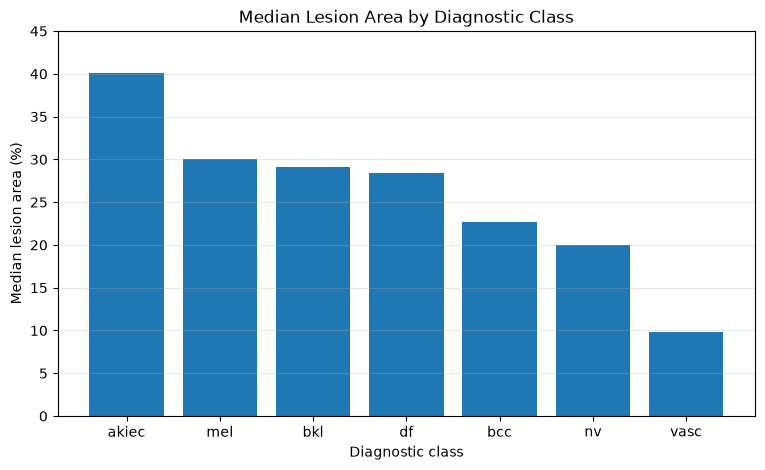

In [26]:
classes = class_area_stats["dx"].to_list()
medians = class_area_stats["median_area_pct"].to_list()

plt.figure(figsize=(9, 5))
plt.bar(classes, medians)

plt.xlabel("Diagnostic class")
plt.ylabel("Median lesion area (%)")
plt.title("Median Lesion Area by Diagnostic Class")
plt.ylim(0, 45)
plt.grid(axis="y", alpha=0.3)

plt.show()

## 3. Data Leakage and Lesion Groups

Multiple images may belong to the same lesion.


In [20]:
lesion_counts = (
    metadata
    .group_by("lesion_id")
    .agg(pl.len().alias("image_count"))
)

multiple_image_lesions = lesion_counts.filter(
    pl.col("image_count") > 1
)

images_in_repeated_lesions = multiple_image_lesions[
    "image_count"
].sum()

print("Total images:", metadata.height)
print("Unique lesions:", lesion_counts.height)
print("Lesions with multiple images:", multiple_image_lesions.height)
print("Images belonging to repeated lesions:", images_in_repeated_lesions)
print("Maximum images per lesion:", lesion_counts["image_count"].max())

Total images: 10015
Unique lesions: 7470
Lesions with multiple images: 1956
Images belonging to repeated lesions: 4501
Maximum images per lesion: 6


**Findings:**

- The dataset has 10,015 images but only 7,470 different lesions.
- 1,956 lesions have more than one image.
- 4,501 images (44.9%) are from lesions that have multiple photos.
- One lesion can have up to 6 images.

If we randomly split the images into training, validation and test sets, photos of the same lesion could end up in different sets. This could cause data leakage and make the model results look better than they actually are.

We should split the data using `lesion_id`, so all images of the same lesion stay in the same set.

## 4. Exact Image Duplicates

We calculate SHA-256 hashes of all image files to detect
files with identical binary content but different filenames.

In [21]:
import hashlib
from collections import defaultdict

hash_groups = defaultdict(list)

for path in tqdm(image_files, desc="Checking exact duplicates"):
    file_hash = hashlib.sha256(path.read_bytes()).hexdigest()
    hash_groups[file_hash].append(path.name)

duplicate_groups = [
    names
    for names in hash_groups.values()
    if len(names) > 1
]

print("Images checked:", len(image_files))
print("Exact duplicate groups:", len(duplicate_groups))
print(
    "Images in duplicate groups:",
    sum(len(group) for group in duplicate_groups)
)

for group in duplicate_groups[:5]:
    print(group)

Checking exact duplicates: 100%|██████████| 10015/10015 [00:13<00:00, 732.52it/s]

Images checked: 10015
Exact duplicate groups: 2
Images in duplicate groups: 4
['ISIC_0024366.jpg', 'ISIC_0029861.jpg']
['ISIC_0024777.jpg', 'ISIC_0029938.jpg']


**Exact duplicate findings:**

- SHA-256 hashing identified 2 groups of byte-identical image files.
- These groups contain 4 images in total.
- The duplicate pairs have different image identifiers.
- Duplicate images could cause data leakage if placed in different splits.


In [22]:
duplicate_ids = [
    Path(name).stem
    for group in duplicate_groups
    for name in group
]

metadata.filter(
    pl.col("image_id").is_in(duplicate_ids)
).select(
    "image_id",
    "lesion_id",
    "dx"
).sort("lesion_id")

image_id,lesion_id,dx
str,str,str
"""ISIC_0029938""","""HAM_0001895""","""nv"""
"""ISIC_0024777""","""HAM_0001895""","""nv"""
"""ISIC_0029861""","""HAM_0002300""","""nv"""
"""ISIC_0024366""","""HAM_0002300""","""nv"""


**Duplicate leakage assessment:**

- We found two pairs of completely identical images.
- Both pairs belong to the `nv` class.
- Images in each pair have the same `lesion_id`.
- By splitting the data using `lesion_id`, we make sure that these duplicate images stay in the same set. This prevents them from causing data leakage between training, validation and test sets.


## 5. Train / Validation / Test Split

We propose a 70/15/15 split grouped by `lesion_id`.

All images belonging to the same lesion must remain in the same
subset to prevent lesion-level data leakage.

Before splitting, we check whether each lesion has a consistent
diagnostic label.

In [27]:
lesion_labels = (
    metadata
    .group_by("lesion_id")
    .agg(
        pl.len().alias("image_count"),
        pl.col("dx").n_unique().alias("n_diagnoses"),
        pl.col("dx").first().alias("dx"),
    )
)

inconsistent_lesions = lesion_labels.filter(
    pl.col("n_diagnoses") > 1
)

print("Unique lesions:", lesion_labels.height)
print(
    "Lesions with conflicting diagnoses:",
    inconsistent_lesions.height
)

inconsistent_lesions.head()

Unique lesions: 7470
Lesions with conflicting diagnoses: 0


lesion_id,image_count,n_diagnoses,dx
str,u32,u32,str


**Label consistency check:**

All 7,470 different lesions have the same diagnosis across their images. We didn't find any lesions with different labels.

Now we can split the dataset using `lesion_id`, while also trying to keep a similar distribution of diagnostic classes in each set.

In [28]:
rng = np.random.default_rng(42)

split_assignments = []

for dx in sorted(lesion_labels["dx"].unique().to_list()):
    class_lesions = (
        lesion_labels
        .filter(pl.col("dx") == dx)
        .sort("lesion_id")
    )

    lesion_ids = class_lesions["lesion_id"].to_list()
    rng.shuffle(lesion_ids)

    n = len(lesion_ids)
    n_train = round(n * 0.70)
    n_val = round(n * 0.15)

    for i, lesion_id in enumerate(lesion_ids):
        if i < n_train:
            split = "train"
        elif i < n_train + n_val:
            split = "val"
        else:
            split = "test"

        split_assignments.append({
            "lesion_id": lesion_id,
            "split": split,
        })

lesion_splits = pl.DataFrame(split_assignments)

image_splits = metadata.join(
    lesion_splits,
    on="lesion_id",
    how="inner"
)

print("Total assigned images:", image_splits.height)
print("Unique assigned lesions:", lesion_splits.height)

print("\nImages per split:")
print(
    image_splits
    .group_by("split")
    .agg(
        pl.len().alias("images"),
        (pl.len() * 100 / metadata.height)
            .round(2).alias("percentage")
    )
    .sort("split")
)

Total assigned images: 10015
Unique assigned lesions: 7470

Images per split:
shape: (3, 3)
┌───────┬────────┬────────────┐
│ split ┆ images ┆ percentage │
│ ---   ┆ ---    ┆ ---        │
│ str   ┆ u32    ┆ f64        │
╞═══════╪════════╪════════════╡
│ test  ┆ 1520   ┆ 15.18      │
│ train ┆ 6982   ┆ 69.72      │
│ val   ┆ 1513   ┆ 15.11      │
└───────┴────────┴────────────┘


In [29]:
lesion_split_counts = (
    image_splits
    .group_by("lesion_id")
    .agg(
        pl.col("split").n_unique().alias("number_of_splits")
    )
)

leaking_lesions = lesion_split_counts.filter(
    pl.col("number_of_splits") > 1
)

print("Lesions appearing in multiple splits:", leaking_lesions.height)
print("Images assigned:", image_splits.height)
print("Unique image IDs:", image_splits["image_id"].n_unique())

assert leaking_lesions.height == 0
assert image_splits.height == metadata.height
assert image_splits["image_id"].n_unique() == metadata.height

print("All split integrity checks passed!")

Lesions appearing in multiple splits: 0
Images assigned: 10015
Unique image IDs: 10015
All split integrity checks passed!


### 5.1 Split Integrity and Class Distribution

We check if all 10,015 images are included in the split and if each image belongs to only one set. We also make sure that images of the same lesion don't end up in different sets, to avoid data leakage.

We then compare how the diagnostic classes are distributed between the training, validation and test sets.

In [30]:
split_class_counts = (
    image_splits
    .group_by(["split", "dx"])
    .agg(pl.len().alias("count"))
    .with_columns(
        (
            pl.col("count") * 100
            / pl.col("count").sum().over("split")
        ).round(2).alias("percentage")
    )
    .sort(["dx", "split"])
)

split_class_counts

split,dx,count,percentage
str,str,u32,f64
"""test""","""akiec""",45,2.96
"""train""","""akiec""",235,3.37
"""val""","""akiec""",47,3.11
"""test""","""bcc""",78,5.13
"""train""","""bcc""",351,5.03
…,…,…,…
"""train""","""nv""",4663,66.79
"""val""","""nv""",1014,67.02
"""test""","""vasc""",19,1.25


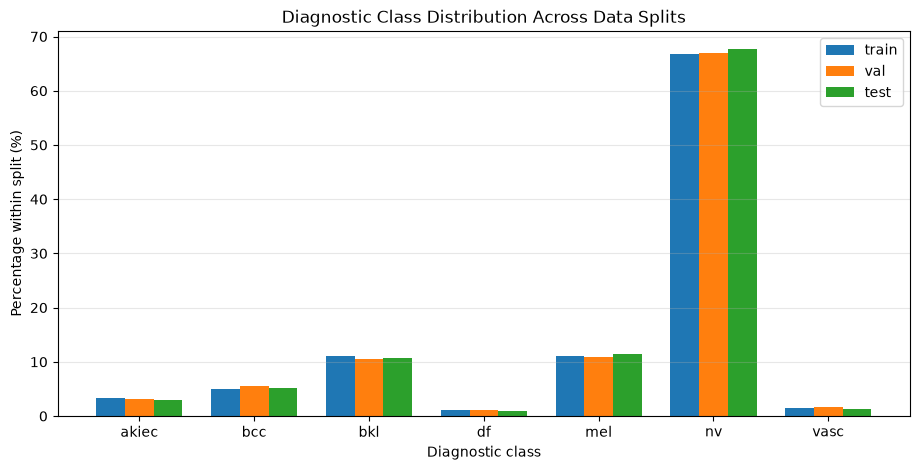

In [31]:
classes = sorted(metadata["dx"].unique().to_list())
splits = ["train", "val", "test"]

x = np.arange(len(classes))
width = 0.25

plt.figure(figsize=(11, 5))

for i, split in enumerate(splits):
    percentages = []

    for dx in classes:
        value = split_class_counts.filter(
            (pl.col("split") == split) &
            (pl.col("dx") == dx)
        )["percentage"]

        percentages.append(value.item() if len(value) else 0)

    plt.bar(
        x + (i - 1) * width,
        percentages,
        width,
        label=split
    )

plt.xticks(x, classes)
plt.xlabel("Diagnostic class")
plt.ylabel("Percentage within split (%)")
plt.title("Diagnostic Class Distribution Across Data Splits")
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

### 5.2 Split Findings

We split the dataset into training, validation and test sets using a 70/15/15 ratio. We used `lesion_id` to keep images of the same lesion together and tried to keep a similar number of images from each diagnostic class in all three sets.

**Results:**

- Training set: 6,982 images (69.72%).
- Validation set: 1,513 images (15.11%).
- Test set: 1,520 images (15.18%).
- All 10,015 images are included in the split.
- No lesion appears in more than one set.
- The distribution of diagnostic classes is similar in all three sets.

**Conclusion:**

This split helps us avoid data leakage because images of the same lesion stay in the same set.

The `nv` class has many more images than the other classes.

